# 01 · Validação do cálculo de terreno

O objetivo é **medir o erro** do nosso gradiente de Horn contra superfícies cuja declividade é conhecida, e mostrar como a resolução e o ruído vertical do DEM alteram as estatísticas. Nada aqui valida o DEM contra o terreno real: isso exige levantamento de campo.

**Perguntas:** (1) o código acerta declividade e aspecto em superfícies analíticas? (2) quanto a resolução de ~30 m subestima a declividade? (3) quanto o erro vertical especificado (< 4 m) infla ou desloca os resultados?

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("TSI_MODE", "demo")
sys.path.insert(0, str(ROOT / "backend"))
warnings.filterwarnings("ignore")
import numpy as np, rasterio, matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from rasterio.transform import from_origin
from app.core import terrain, dem as demmod, soil as soilmod, zonal, geometry as geom, contours
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
with rasterio.open(ROOT / "sample_data/demo_dem_glo30.tif") as s:
    DEM, TR = s.read(1), s.transform


## 1. Planos inclinados: erro de declividade e de aspecto

Construímos planos com gradiente exato (em m/m) em uma grade geográfica de 1" a 22,2°S. O aspecto esperado é o azimute da **descida**.

In [2]:
def plane(sx, sy, n=40, lat0=-22.2, lon0=-46.8, res=1/3600):
    tr = from_origin(lon0, lat0 + n*res/2, res, res)
    dx, dy = terrain.cell_size_m(tr, n)
    j, i = np.arange(n)[None, :], np.arange(n)[:, None]
    return (500 + sx*j*dx[:, None] - sy*i*dy.mean()).astype("float32"), tr

rows = []
for pct in (1, 5, 10, 30, 60, 100):
    for az in range(0, 360, 45):
        sx = -np.sin(np.radians(az)) * pct/100   # subir para o lado oposto à descida
        sy = -np.cos(np.radians(az)) * pct/100
        z, tr = plane(sx, sy)
        sl, a = terrain.slope_aspect(z, tr)
        core = (slice(3, -3), slice(3, -3))
        pct_est = float(np.nanmean(terrain.slope_pct(sl[core])))
        da = float(np.nanmax(np.abs(((a[core] - az + 180) % 360) - 180))) if pct > 1 else np.nan
        rows.append((pct, az, pct_est, abs(pct_est - pct)/pct*100, da))
import pandas as pd
df = pd.DataFrame(rows, columns=["declividade_real_%", "aspecto_real", "declividade_est_%", "erro_rel_%", "erro_aspecto_graus"])
print(df.groupby("declividade_real_%")[["erro_rel_%", "erro_aspecto_graus"]].max().round(3))
print("\nErro relativo máximo de declividade:", round(df["erro_rel_%"].max(), 3), "% · erro máximo de aspecto:", round(df["erro_aspecto_graus"].max(), 3), "°")

                    erro_rel_%  erro_aspecto_graus
declividade_real_%                                
1                        0.002                 NaN
5                        0.002               0.005
10                       0.002               0.004
30                       0.002               0.004
60                       0.002               0.004
100                      0.002               0.004

Erro relativo máximo de declividade: 0.002 % · erro máximo de aspecto: 0.005 °


**Leitura.** Em planos exatos o erro relativo máximo de declividade é de ~0,002% e o de aspecto, de ~0,005° (resíduo da pequena variação de dx/dy com a latitude dentro da grade). O cálculo está correto como *aritmética*. Isso não diz nada sobre quanto o DEM representa o terreno.

## 2. Superfície curva (paraboloide): viés do kernel 3×3

Para z = k·r², a declividade exata a distância r do vértice é arctan(2kr). Testamos se a diferença finita de Horn tem viés em superfícies curvas.

k=0.0001: erro médio +0.0000° · máx |erro| 0.0006°
k=0.0005: erro médio +0.0000° · máx |erro| 0.0009°
k=0.002: erro médio -0.0000° · máx |erro| 0.0003°


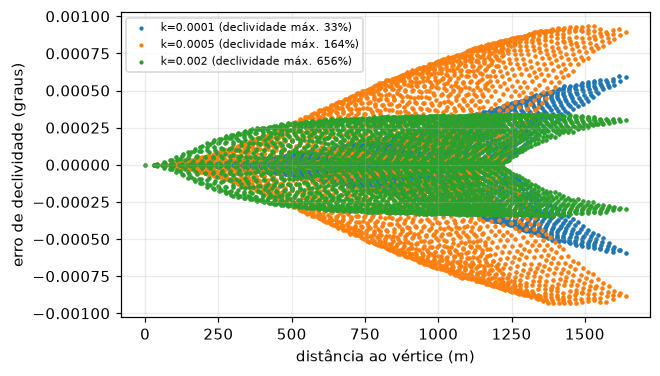

In [3]:
n = 81; res = 1/3600; lat0 = -22.2
tr = from_origin(-46.8, lat0 + n*res/2, res, res)
dx, dy = terrain.cell_size_m(tr, n)
X = (np.arange(n)[None, :] - n//2) * dx.mean(); Y = (np.arange(n)[:, None] - n//2) * dy.mean()
R = np.hypot(X, Y)
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for k in (1e-4, 5e-4, 2e-3):
    z = (k * R**2).astype("float32")
    sl, _ = terrain.slope_aspect(z, tr)
    exact = np.degrees(np.arctan(2*k*R))
    err = (sl - exact)
    m = np.isfinite(err)
    ax.scatter(R[m], err[m], s=3, label=f"k={k:g} (declividade máx. {np.nanmax(terrain.slope_pct(sl)):.0f}%)")
    print(f"k={k:g}: erro médio {np.nanmean(err):+.4f}° · máx |erro| {np.nanmax(np.abs(err)):.4f}°")
ax.set_xlabel("distância ao vértice (m)"); ax.set_ylabel("erro de declividade (graus)"); ax.legend(fontsize=7); plt.show()

**Leitura.** Nos três casos o erro máximo é < 0,001°: para uma superfície quadrática o kernel de Horn praticamente não tem viés. Isso vale para a *aritmética* sobre uma superfície suave; o DEM real tem feições abaixo de 30 m que o kernel não vê.

## 3. Resolução: quanto a declividade 'some' ao agregar o DEM

Agregamos o DEM real (média em blocos) de 30 m para 60, 90, 150 e 300 m e recalculamos. Isso mostra, com dados reais, por que **declividade de 30 m subestima a declividade local** e por que números de declividade de DEMs de resoluções diferentes não são comparáveis.

resolução  declividade média (%)   P95 (%)  % da área ≥ 20% (forte ondulado+)
     30 m                  14.16 31.070000                              18.38
     60 m                  12.13 25.790001                              11.27
     90 m                  10.74 22.680000                               7.46
    150 m                   8.69 18.700001                               4.15
    300 m                   5.95 13.830000                               1.37


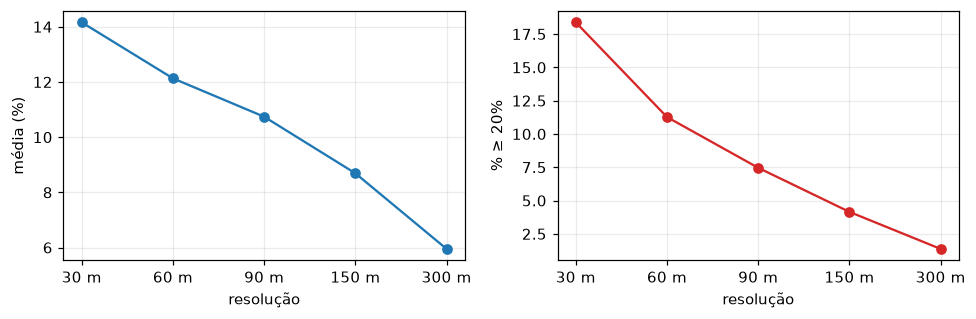

In [4]:
def aggregate(z, f):
    h, w = (z.shape[0]//f)*f, (z.shape[1]//f)*f
    return np.nanmean(z[:h, :w].reshape(h//f, f, w//f, f), axis=(1, 3))
res_rows = []
for f in (1, 2, 3, 5, 10):
    zz = aggregate(DEM, f) if f > 1 else DEM
    tr_f = from_origin(TR.c, TR.f, abs(TR.a)*f, abs(TR.e)*f)
    sl, _ = terrain.slope_aspect(zz.astype("float32"), tr_f)
    p = terrain.slope_pct(sl[np.isfinite(sl)])
    res_rows.append((f"{30*f} m", p.mean(), np.percentile(p, 95), (p >= 20).mean()*100))
r = pd.DataFrame(res_rows, columns=["resolução", "declividade média (%)", "P95 (%)", "% da área ≥ 20% (forte ondulado+)"]).round(2)
print(r.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(r["resolução"], r["declividade média (%)"], "o-"); ax[0].set_ylabel("média (%)"); ax[0].set_xlabel("resolução")
ax[1].plot(r["resolução"], r["% da área ≥ 20% (forte ondulado+)"], "o-", color="C3"); ax[1].set_ylabel("% ≥ 20%"); ax[1].set_xlabel("resolução")
plt.tight_layout(); plt.show()

## 4. Ruído vertical: efeito do erro do DEM sobre a declividade

A especificação do Copernicus DEM dá exatidão vertical absoluta < 4 m (LE90). O erro **relativo** entre pixels vizinhos é o que importa para declividade e ele é, em geral, menor, mas não o conhecemos para esta área. Simulamos ruído aleatório (independente por pixel, hipótese simples) de σ = 0,5, 1, 2 e 4 m **só para dimensionar a sensibilidade**, não para estimar o erro real.

In [5]:
rng = np.random.default_rng(42)
base_sl, _ = terrain.slope_aspect(DEM, TR)
b = terrain.slope_pct(base_sl[np.isfinite(base_sl)])
out = [("0 (original)", b.mean(), np.percentile(b, 95), (b < 3).mean()*100)]
for sig in (0.5, 1, 2, 4):
    z = (DEM + rng.normal(0, sig, DEM.shape)).astype("float32")
    sl, _ = terrain.slope_aspect(z, TR)
    p = terrain.slope_pct(sl[np.isfinite(sl)])
    out.append((f"σ = {sig} m", p.mean(), np.percentile(p, 95), (p < 3).mean()*100))
nr = pd.DataFrame(out, columns=["ruído", "declividade média (%)", "P95 (%)", "% 'plano' (<3%)"]).round(2)
print(nr.to_string(index=False))

       ruído  declividade média (%)   P95 (%)  % 'plano' (<3%)
0 (original)                  14.16 31.070000             3.01
   σ = 0.5 m                  14.19 31.120001             2.99
     σ = 1 m                  14.28 31.250000             2.98
     σ = 2 m                  14.62 31.690001             3.06
     σ = 4 m                  15.97 33.639999             2.82


**Leitura.** Ruído independente por pixel *infla* a declividade (média e P95) de forma modesta: de 14,16% para 14,62% com σ = 2 m e 15,97% com σ = 4 m. A fatia 'plano' (< 3%) quase não muda (3,01% → 2,82%). O kernel 3×3 já faz alguma suavização. Este teste assume ruído independente por pixel; o erro real do DEM é espacialmente correlacionado e não o conhecemos para esta área, então o resultado dimensiona a sensibilidade e não prova que a declividade é confiável. Por isso o relatório não trata a declividade de 30 m como medida precisa e não usa limiares operacionais.

## 5. Curvas de nível: incerteza horizontal implícita no intervalo

Uma curva de cota *h* tem posição incerta de ≈ σᵥ / tan(β) na horizontal, onde β é a declividade. Com σᵥ de 4 m e 12% (mediana da área), a incerteza horizontal é de dezenas de metros, comparável ao pixel. Isso justifica o piso de 5 m e o padrão de 10 m.

In [6]:
sl_pct = terrain.slope_pct(base_sl[np.isfinite(base_sl)])
for sv in (1, 2, 4):
    q = np.percentile(sl_pct, [10, 50, 90])
    print(f"σv = {sv} m → incerteza horizontal da curva: P10 {sv/(q[0]/100):.0f} m · mediana {sv/(q[1]/100):.0f} m · P90 {sv/(q[2]/100):.0f} m (declividades P10/P50/P90 = {q.round(1)}%)")
rel = float(np.nanmax(DEM) - np.nanmin(DEM))
print("\nRelevo do recorte:", round(rel), "m → intervalo recomendado:", contours.recommended_interval(rel), "m")
print("Intervalo de 2 m →", end=" ")
try: contours.check_interval(2)
except ValueError as e: print("recusado:", str(e)[:90], "…")

σv = 1 m → incerteza horizontal da curva: P10 18 m · mediana 8 m · P90 4 m (declividades P10/P50/P90 = [ 5.6 12.3 25.1]%)
σv = 2 m → incerteza horizontal da curva: P10 36 m · mediana 16 m · P90 8 m (declividades P10/P50/P90 = [ 5.6 12.3 25.1]%)
σv = 4 m → incerteza horizontal da curva: P10 72 m · mediana 32 m · P90 16 m (declividades P10/P50/P90 = [ 5.6 12.3 25.1]%)

Relevo do recorte: 443 m → intervalo recomendado: 50.0 m
Intervalo de 2 m → recusado: Intervalo 2 m incoerente com o DEM GLO-30 (exatidão vertical especificada < 4 m LE90, célu …


## Conclusões

1. O gradiente de Horn com dx/dy por latitude **reproduz** declividade e aspecto de planos exatos com erro desprezível, e tem viés pequeno e conhecido em superfícies curvas.
2. A **resolução** domina: agregar de 30 m para 150 m reduz a declividade média de 14,2% para 8,7% e a área ≥ 20% de 18,4% para 4,2%; os valores não são comparáveis entre resoluções.
3. O **ruído vertical** infla a declividade de forma modesta nesta área (+13% na média com σ = 4 m, +3% com σ = 2 m); a classe 'plano' praticamente não muda. O efeito mais relevante do erro vertical é na **posição das curvas de nível** (seção 5).
4. Com σᵥ = 4 m, a posição horizontal de uma curva é incerta em ~32 m na declividade mediana (≈ 1 pixel) e em ~72 m nas áreas mais suaves; por isso o padrão é ≥ 10 m e intervalos < 5 m são recusados.

**Não validado aqui:** exatidão do DEM contra o terreno real (precisa de pontos GNSS/levantamento).